In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

#setez un seed ca datele sa primesc aceeasi 1000 de studenti nu altii noi
np.random.seed(10)
numar_studenti = 1000

#generez coloanele de baza
domenii = ['IT', 'Medicina', 'Drept', 'Litere']
#pun probabilitatile
domeniu_facultate = np.random.choice(domenii, numar_studenti, p=[0.35, 0.35, 0.15, 0.15])
#setez media un numar real intre 6.0 si 10.0
medie = np.random.uniform(6.0, 10.0, numar_studenti).round(2)
limbi_straine = np.random.randint(0, 4, numar_studenti)
erasmus = np.random.choice(['Da', 'Nu'], numar_studenti, p=[0.2, 0.8])
experienta = np.random.choice(['Da', 'Nu'], numar_studenti)
stres_financiar = np.random.randint(1, 11, numar_studenti)

#calculez un salariu asteptat, dar diferit in functie de domeniu
salariu = []
for d in domeniu_facultate:
    if d == 'IT': salariu.append(np.random.uniform(1200, 2500))
    elif d == 'Medicina': salariu.append(np.random.uniform(800, 1500))
    elif d == 'Drept': salariu.append(np.random.uniform(600, 1300))
    else: salariu.append(np.random.uniform(500, 900))
salariu_asteptat = np.array(salariu).round(2)

#coloana pt plecarea in strainatate
#creez un scor intern de plecare initial 0
scor_plecare = np.zeros(numar_studenti)
#IT-ul si medicina primesc puncte in plus spre plecare
scor_plecare += np.where((domeniu_facultate == 'IT') | (domeniu_facultate == 'Medicina'), 2, 0)
#mai multe limbi straine sau experienta Erasmus cresc sansele
scor_plecare += limbi_straine * 1.5
scor_plecare += np.where(erasmus == 'Da', 3, 0)
#stresul financiar mare contribuie la plecare
scor_plecare += stres_financiar * 0.3

#daca scorul depaseste un prag, studentul pleaca, altfel ramane
pleaca = np.where(scor_plecare > 5.5, 'Da', 'Nu')

#creez tabelul
df = pd.DataFrame({
    'Domeniu_Facultate': domeniu_facultate,
    'Medie_Absolvire': medie,
    'Numar_Limbi_Straine': limbi_straine,
    'A_fost_cu_Erasmus': erasmus,
    'Salariu_Asteptat_RO_Euro': salariu_asteptat,
    'Are_Experienta_Munca': experienta,
    'Nivel_Stres_Financiar': stres_financiar,
    'Pleaca_in_Strainatate': pleaca
})

#simulez valori lipsa pt cerinta 6
numar_lipsa = 50 #5% din cei 1000 de studenti
# aleg 50 de numere la intamplare pentru salariu
indici_salariu = np.random.choice(df.index, numar_lipsa, replace=False)
df.loc[indici_salariu, 'Salariu_Asteptat_RO_Euro'] = np.nan
#aleg alte 50 de numere la intamplare pentru experienta
indici_experienta = np.random.choice(df.index, numar_lipsa, replace=False)
df.loc[indici_experienta, 'Are_Experienta_Munca'] = np.nan

#impartirea datelor pt cerinta 7, 70% antrenare, 30% testare
train_df, test_df = train_test_split(df, test_size=0.3, random_state=10)

#salvarea
train_df.to_csv('train.csv', index=False)
test_df.to_csv('test.csv', index=False)

print(f"Datele tale unice au fost generate! S-au salvat {len(train_df)} randuri pentru antrenare si {len(test_df)} pentru testare.")

Datele tale unice au fost generate! S-au salvat 700 randuri pentru antrenare si 300 pentru testare.


In [2]:
#verific pentru subsetul de antrenare
print("Date lipsa in antrenare")
lipsa_train = train_df.isnull().sum()
procent_train = (lipsa_train / len(train_df)) * 100

#afisez coloanele care au probleme
print("Numar valori lipsa:\n", lipsa_train[lipsa_train > 0])
print("\nProcentaj (%):\n", procent_train[procent_train > 0].round(2))

#verific pt subsetul de testare
print("\nDate lipsa in testare")
lipsa_test = test_df.isnull().sum()
procent_test = (lipsa_test / len(test_df)) * 100

print("Numar valori lipsa:\n", lipsa_test[lipsa_test > 0])
print("\nProcentaj (%):\n", procent_test[procent_test > 0].round(2))

#repar gaurile din date
#pentru salariu
media_salariu = train_df['Salariu_Asteptat_RO_Euro'].mean()
train_df['Salariu_Asteptat_RO_Euro'] = train_df['Salariu_Asteptat_RO_Euro'].fillna(media_salariu)
test_df['Salariu_Asteptat_RO_Euro'] = test_df['Salariu_Asteptat_RO_Euro'].fillna(media_salariu)
#pentru experienta de munca
mod_experienta = train_df['Are_Experienta_Munca'].mode()[0]
train_df['Are_Experienta_Munca'] = train_df['Are_Experienta_Munca'].fillna(mod_experienta)
test_df['Are_Experienta_Munca'] = test_df['Are_Experienta_Munca'].fillna(mod_experienta)

print("\nAm inlocuit salariile si experienta lipsa.")

--- Date lipsa in antrenare ---
Numar valori lipsa:
 Salariu_Asteptat_RO_Euro    33
Are_Experienta_Munca        34
dtype: int64

Procentaj (%):
 Salariu_Asteptat_RO_Euro    4.71
Are_Experienta_Munca        4.86
dtype: float64

--- Date lipsa in testare ---
Numar valori lipsa:
 Salariu_Asteptat_RO_Euro    17
Are_Experienta_Munca        16
dtype: int64

Procentaj (%):
 Salariu_Asteptat_RO_Euro    5.67
Are_Experienta_Munca        5.33
dtype: float64

Am inlocuit salariile si experienta lipsa.


=== Statistici pentru date numerice-antrenare ===


,Medie_Absolvire,Numar_Limbi_Straine,Salariu_Asteptat_RO_Euro,Nivel_Stres_Financiar
count,700.00,700.00,700.00,700.00
mean,8.06,1.51,1319.63,5.44
std,1.15,1.14,504.58,2.89
min,6.01,0.00,500.15,1.00
25%,7.03,0.00,912.56,3.00
50%,8.08,2.00,1261.36,5.00
75%,9.09,3.00,1565.29,8.00
max,10.00,3.00,2496.84,10.00


=== Statistici pentru date numerice-testare ===


,Medie_Absolvire,Numar_Limbi_Straine,Salariu_Asteptat_RO_Euro,Nivel_Stres_Financiar
count,300.00,300.00,300.00,300.00
mean,7.92,1.57,1332.46,5.53
std,1.23,1.13,504.80,2.89
min,6.00,0.00,510.38,1.00
25%,6.78,1.00,912.06,3.00
50%,7.80,2.00,1289.26,5.00
75%,9.04,3.00,1606.72,8.00
max,9.99,3.00,2490.61,10.00



=== Statistici pentru date categoriale-antrenare ===


,Domeniu_Facultate,A_fost_cu_Erasmus,Are_Experienta_Munca,Pleaca_in_Strainatate
count,700,700,700,700
unique,4,2,2,2
top,IT,Nu,Da,Da
freq,260,538,368,397



=== Statistici pentru date categoriale-testare ===


,Domeniu_Facultate,A_fost_cu_Erasmus,Are_Experienta_Munca,Pleaca_in_Strainatate
count,300,300,300,300
unique,4,2,2,2
top,IT,Nu,Da,Da
freq,112,228,159,185


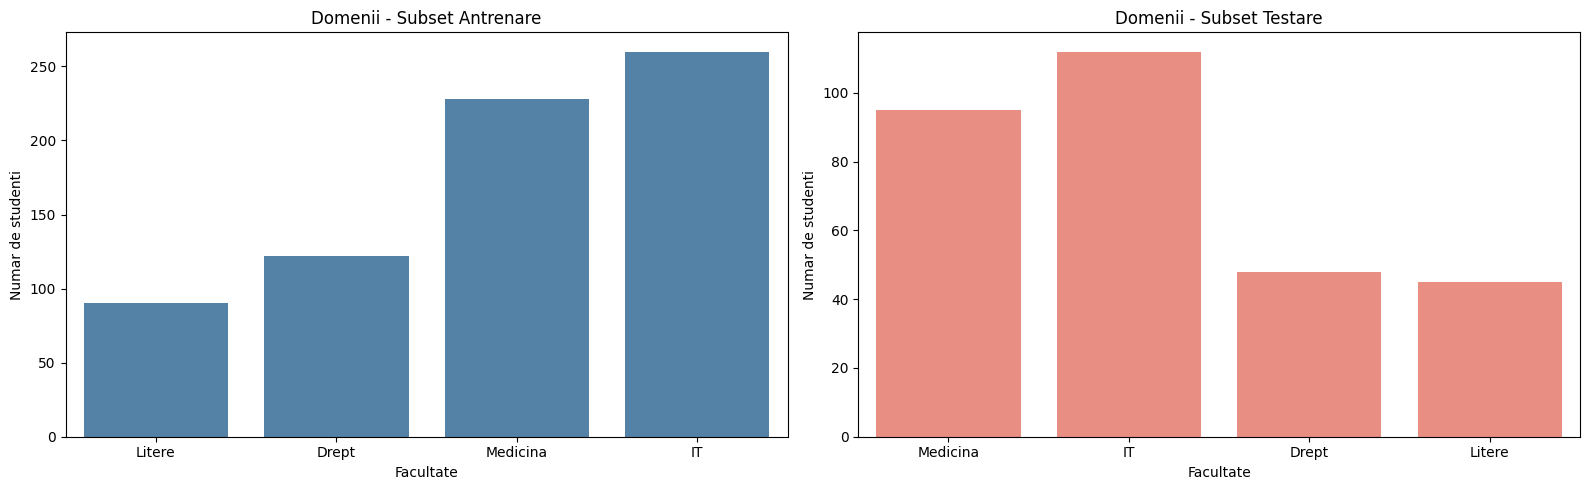

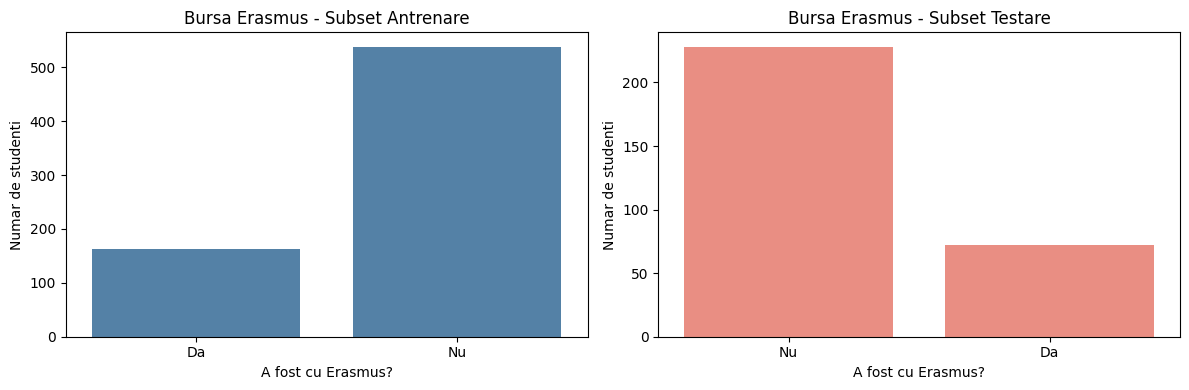

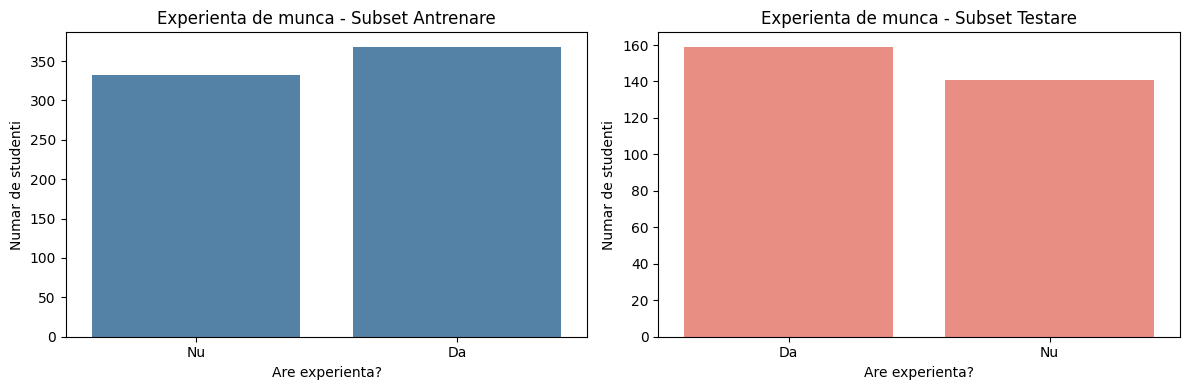

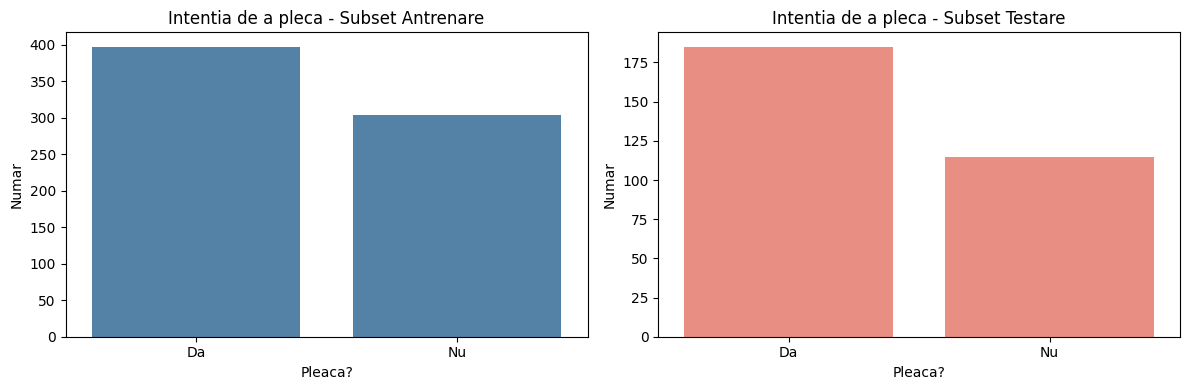

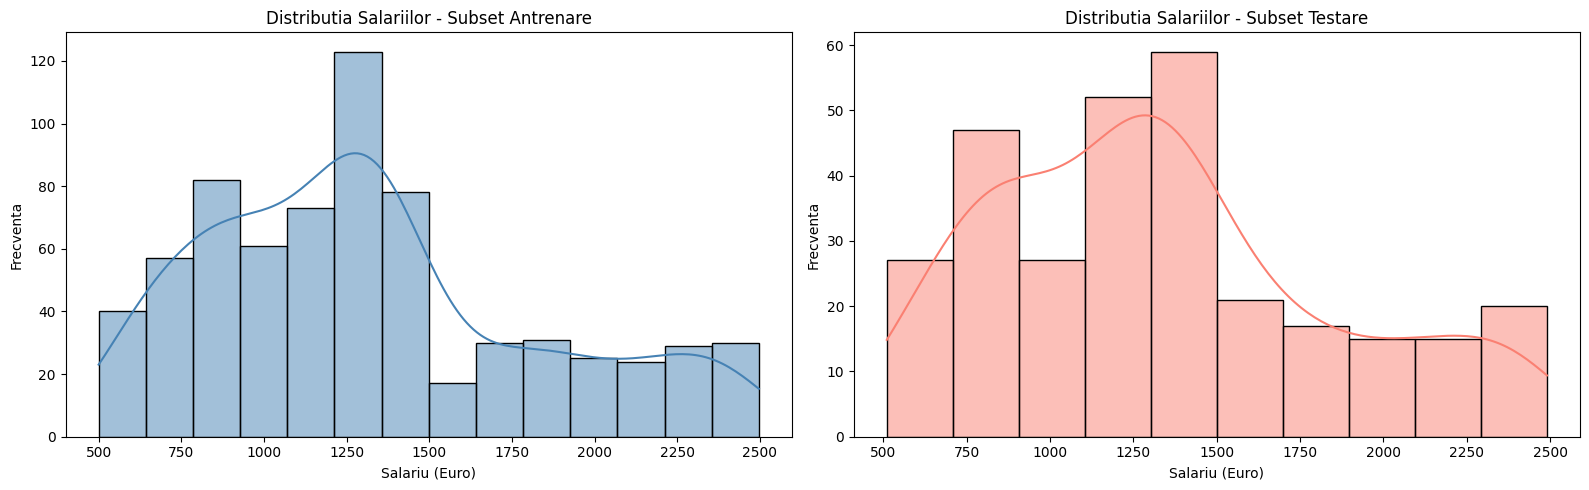

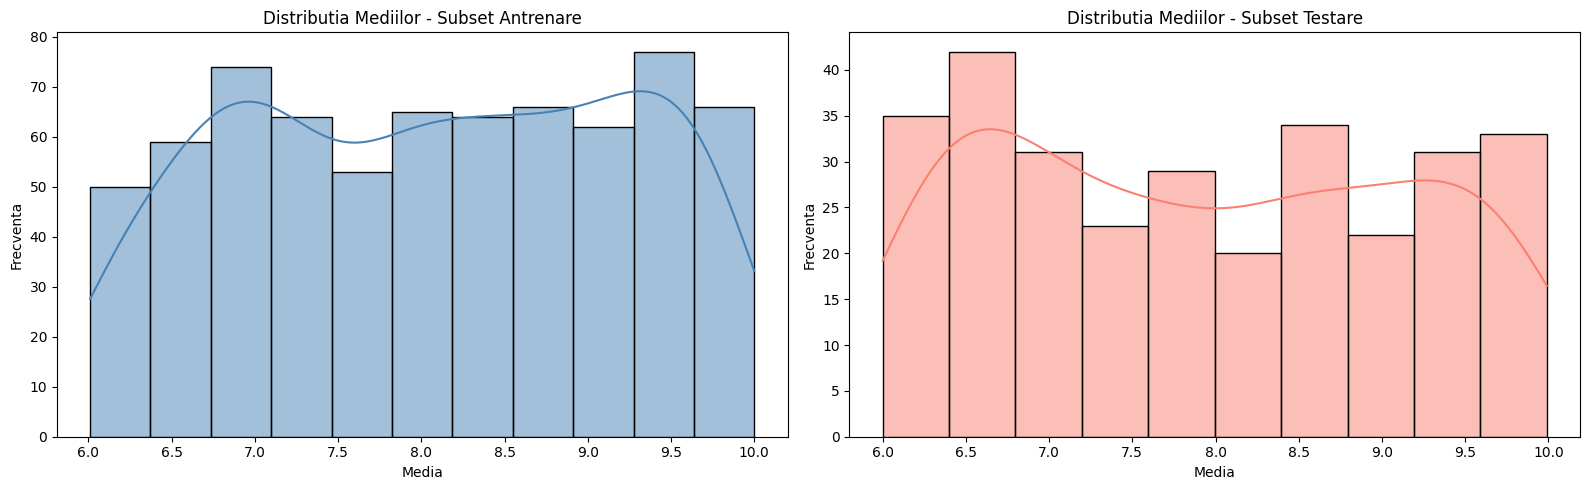

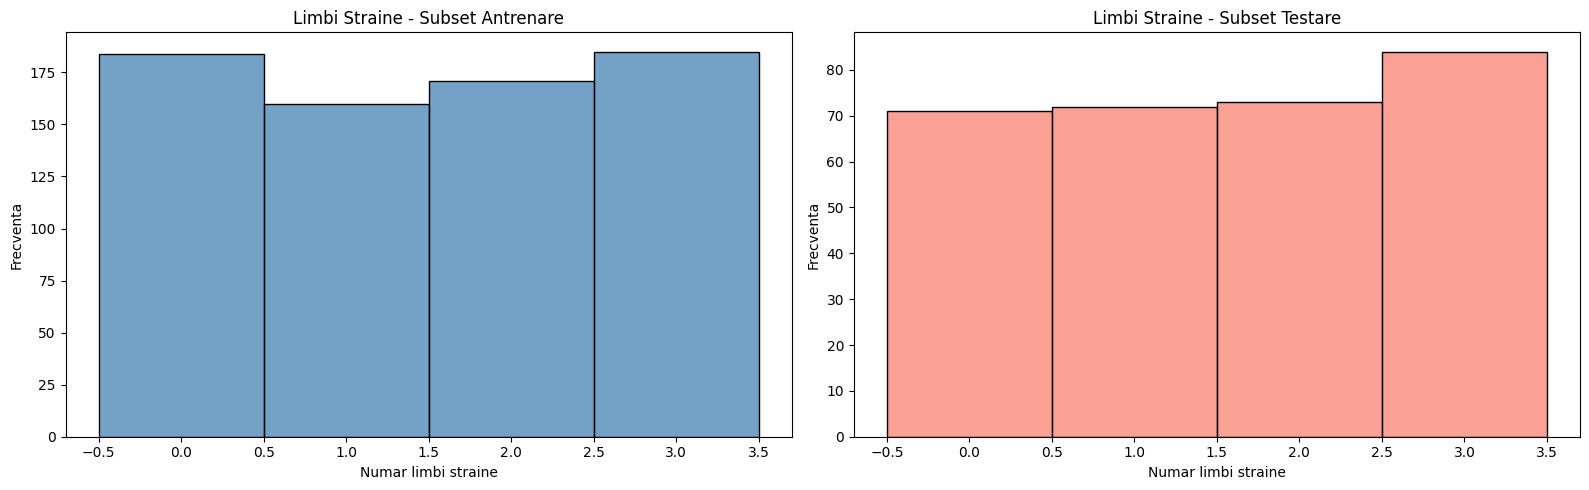

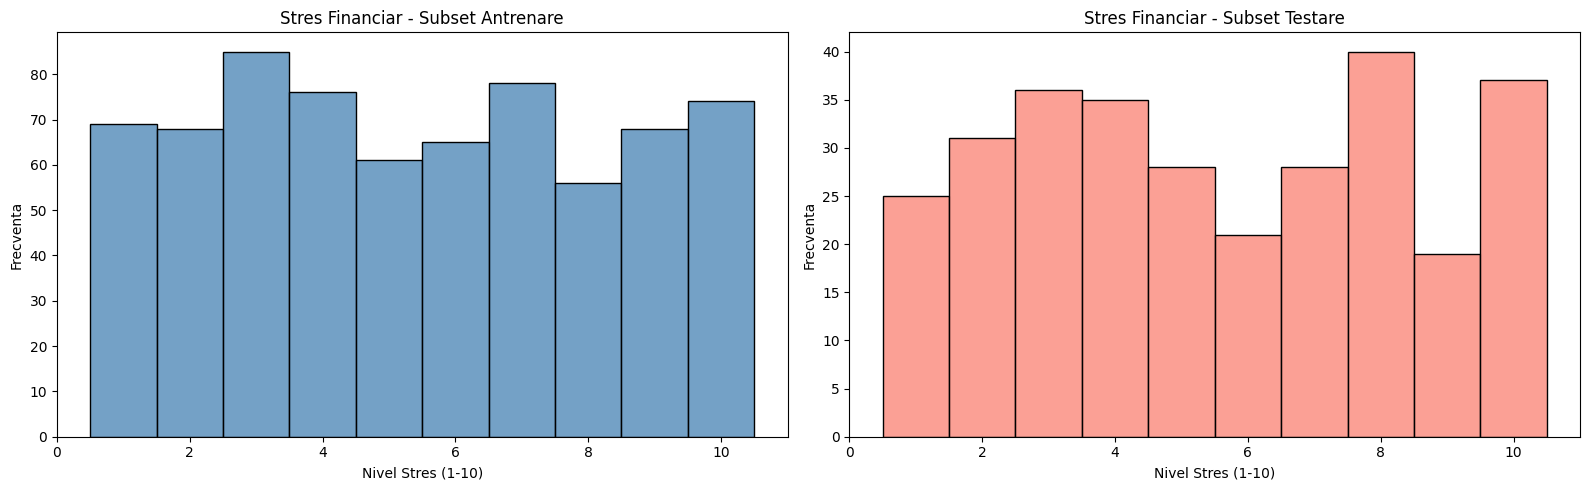

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

#statistici descriptive
print("=== Statistici pentru date numerice-antrenare ===")
display(train_df.describe().round(2))
print("=== Statistici pentru date numerice-testare ===")
display(test_df.describe().round(2))
print("\n=== Statistici pentru date categoriale-antrenare ===")
display(train_df.describe(include='object'))
print("\n=== Statistici pentru date categoriale-testare ===")
display(test_df.describe(include='object'))

#analiza distributiei
#grafic pentru facultate
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=train_df, x='Domeniu_Facultate', ax=axes[0], color='steelblue')
axes[0].set_title('Domenii - Subset Antrenare')
axes[0].set_xlabel('Facultate')
axes[0].set_ylabel('Numar de studenti')

sns.countplot(data=test_df, x='Domeniu_Facultate', ax=axes[1], color='salmon')
axes[1].set_title('Domenii - Subset Testare')
axes[1].set_xlabel('Facultate')
axes[1].set_ylabel('Numar de studenti')
plt.tight_layout()
plt.show()

#grafic cu experienta Erasmus
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train_df, x='A_fost_cu_Erasmus', ax=axes[0], color='steelblue')
axes[0].set_title('Bursa Erasmus - Subset Antrenare')
axes[0].set_xlabel('A fost cu Erasmus?')
axes[0].set_ylabel('Numar de studenti')

sns.countplot(data=test_df, x='A_fost_cu_Erasmus', ax=axes[1], color='salmon')
axes[1].set_title('Bursa Erasmus - Subset Testare')
axes[1].set_xlabel('A fost cu Erasmus?')
axes[1].set_ylabel('Numar de studenti')
plt.tight_layout()
plt.show()

#grafic cu experienta de munca
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train_df, x='Are_Experienta_Munca', ax=axes[0], color='steelblue')
axes[0].set_title('Experienta de munca - Subset Antrenare')
axes[0].set_xlabel('Are experienta?')
axes[0].set_ylabel('Numar de studenti')

sns.countplot(data=test_df, x='Are_Experienta_Munca', ax=axes[1], color='salmon')
axes[1].set_title('Experienta de munca - Subset Testare')
axes[1].set_xlabel('Are experienta?')
axes[1].set_ylabel('Numar de studenti')
plt.tight_layout()
plt.show()

#grafic pentru plecare
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train_df, x='Pleaca_in_Strainatate', ax=axes[0], color='steelblue')
axes[0].set_title('Intentia de a pleca - Subset Antrenare')
axes[0].set_xlabel('Pleaca?')
axes[0].set_ylabel('Numar')

sns.countplot(data=test_df, x='Pleaca_in_Strainatate', ax=axes[1], color='salmon')
axes[1].set_title('Intentia de a pleca - Subset Testare')
axes[1].set_xlabel('Pleaca?')
axes[1].set_ylabel('Numar')
plt.tight_layout()
plt.show()

#histograma pentru salariu asteptat
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=train_df, x='Salariu_Asteptat_RO_Euro', kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distributia Salariilor - Subset Antrenare')
axes[0].set_xlabel('Salariu (Euro)')
axes[0].set_ylabel('Frecventa')

sns.histplot(data=test_df, x='Salariu_Asteptat_RO_Euro', kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distributia Salariilor - Subset Testare')
axes[1].set_xlabel('Salariu (Euro)')
axes[1].set_ylabel('Frecventa')
plt.tight_layout()
plt.show()

#media absolvire
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=train_df, x='Medie_Absolvire', kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distributia Mediilor - Subset Antrenare')
axes[0].set_xlabel('Media')
axes[0].set_ylabel('Frecventa')

sns.histplot(data=test_df, x='Medie_Absolvire', kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distributia Mediilor - Subset Testare')
axes[1].set_xlabel('Media')
axes[1].set_ylabel('Frecventa')
plt.tight_layout()
plt.show()

#numar de limbi straine
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=train_df, x='Numar_Limbi_Straine', discrete=True, ax=axes[0], color='steelblue')
axes[0].set_title('Limbi Straine - Subset Antrenare')
axes[0].set_xlabel('Numar limbi straine')
axes[0].set_ylabel('Frecventa')

sns.histplot(data=test_df, x='Numar_Limbi_Straine', discrete=True, ax=axes[1], color='salmon')
axes[1].set_title('Limbi Straine - Subset Testare')
axes[1].set_xlabel('Numar limbi straine')
axes[1].set_ylabel('Frecventa')
plt.tight_layout()
plt.show()

#nivel stres financiar
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=train_df, x='Nivel_Stres_Financiar', discrete=True, ax=axes[0], color='steelblue')
axes[0].set_title('Stres Financiar - Subset Antrenare')
axes[0].set_xlabel('Nivel Stres (1-10)')
axes[0].set_ylabel('Frecventa')

sns.histplot(data=test_df, x='Nivel_Stres_Financiar', discrete=True, ax=axes[1], color='salmon')
axes[1].set_title('Stres Financiar - Subset Testare')
axes[1].set_xlabel('Nivel Stres (1-10)')
axes[1].set_ylabel('Frecventa')
plt.tight_layout()
plt.show()

=== Boxplot-uri pentru detectarea valorilor aberante ===


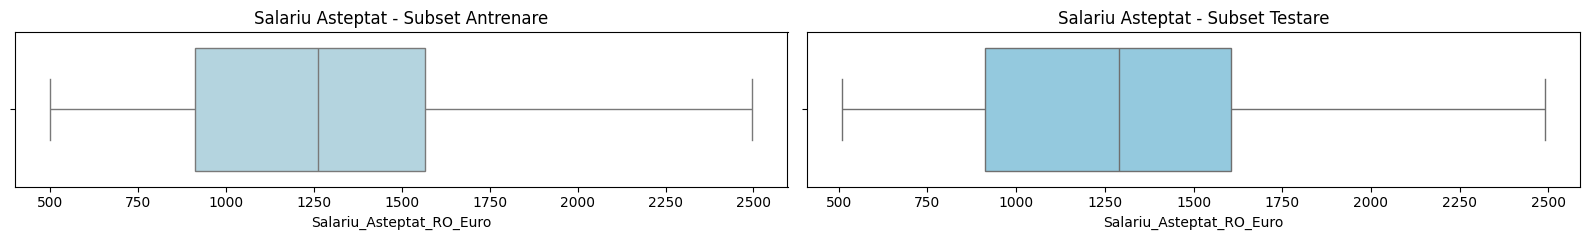

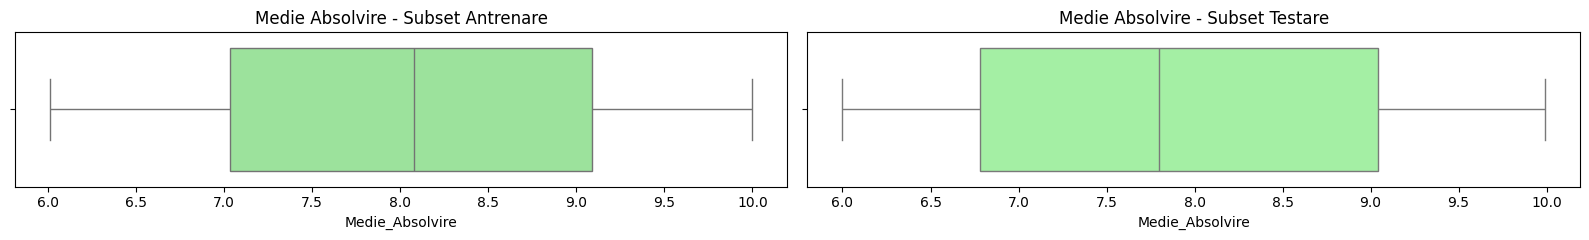

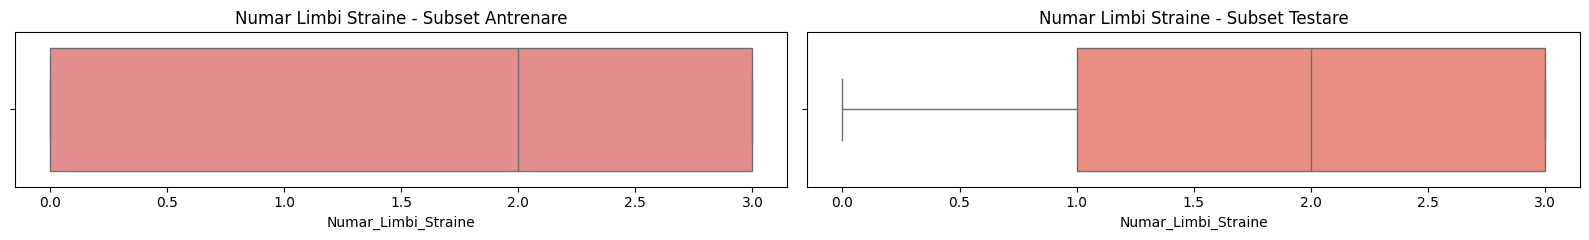

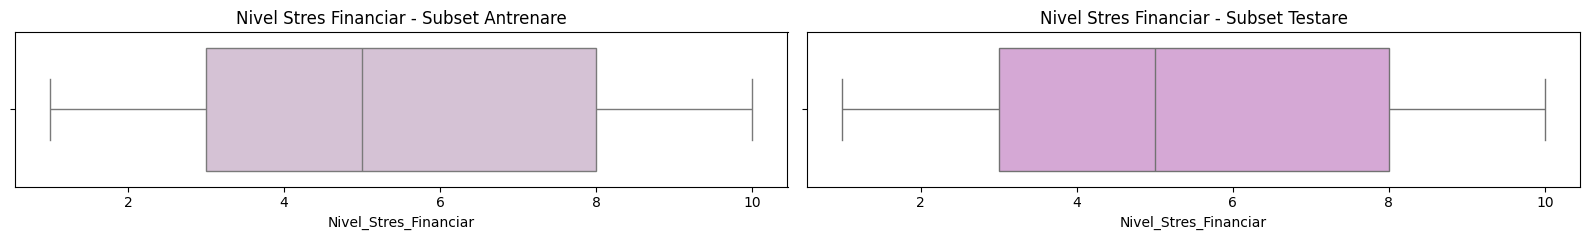

In [4]:
#detectarea outlierilor
print("=== Boxplot-uri pentru detectarea valorilor aberante ===")
#doar pentru valorile numerice

#pentru salariu
fig, axes = plt.subplots(1, 2, figsize=(16, 2.5))
sns.boxplot(data=train_df, x='Salariu_Asteptat_RO_Euro', color='lightblue', ax=axes[0])
axes[0].set_title('Salariu Asteptat - Subset Antrenare')

sns.boxplot(data=test_df, x='Salariu_Asteptat_RO_Euro', color='skyblue', ax=axes[1])
axes[1].set_title('Salariu Asteptat - Subset Testare')
plt.tight_layout()
plt.show()

#pentru medie
fig, axes = plt.subplots(1, 2, figsize=(16, 2.5))
sns.boxplot(data=train_df, x='Medie_Absolvire', color='lightgreen', ax=axes[0])
axes[0].set_title('Medie Absolvire - Subset Antrenare')

sns.boxplot(data=test_df, x='Medie_Absolvire', color='palegreen', ax=axes[1])
axes[1].set_title('Medie Absolvire - Subset Testare')
plt.tight_layout()
plt.show()

#pentru limbi straine
fig, axes = plt.subplots(1, 2, figsize=(16, 2.5))
sns.boxplot(data=train_df, x='Numar_Limbi_Straine', color='lightcoral', ax=axes[0])
axes[0].set_title('Numar Limbi Straine - Subset Antrenare')

sns.boxplot(data=test_df, x='Numar_Limbi_Straine', color='salmon', ax=axes[1])
axes[1].set_title('Numar Limbi Straine - Subset Testare')
plt.tight_layout()
plt.show()

#pentru stres financiar
fig, axes = plt.subplots(1, 2, figsize=(16, 2.5))
sns.boxplot(data=train_df, x='Nivel_Stres_Financiar', color='thistle', ax=axes[0])
axes[0].set_title('Nivel Stres Financiar - Subset Antrenare')

sns.boxplot(data=test_df, x='Nivel_Stres_Financiar', color='plum', ax=axes[1])
axes[1].set_title('Nivel Stres Financiar - Subset Testare')
plt.tight_layout()
plt.show()

=== Matricea de corelatie ===


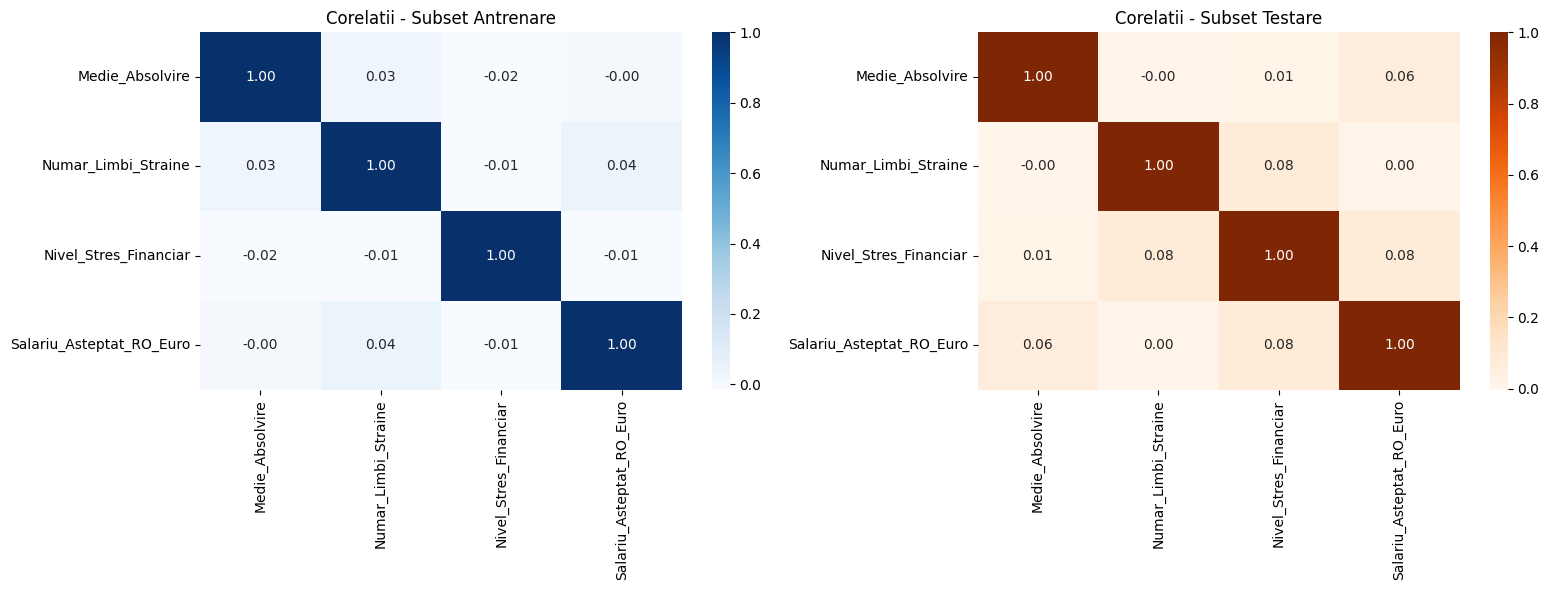


=== Relatia variabilelor cu intentia de plecare ===


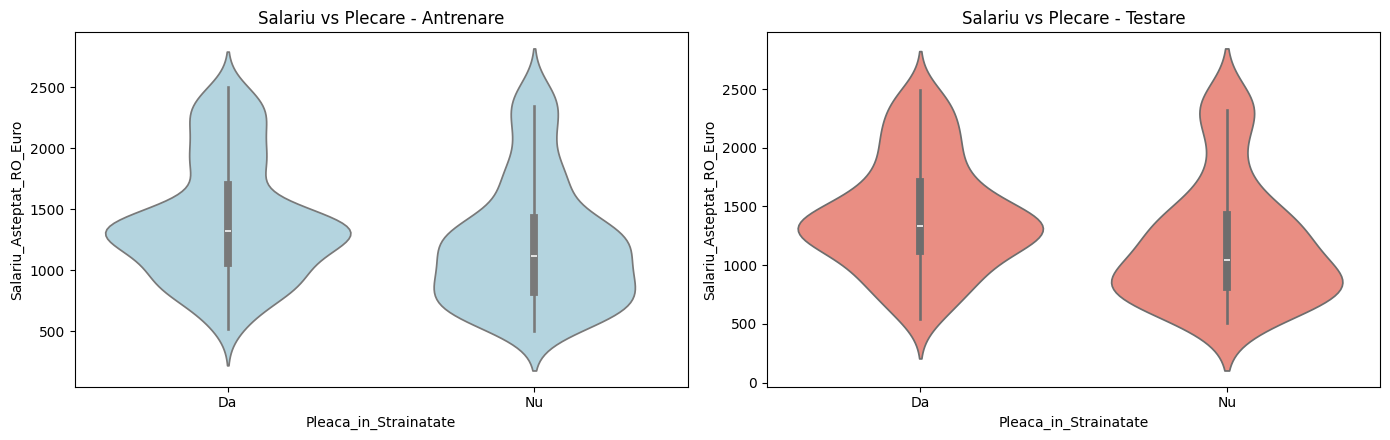

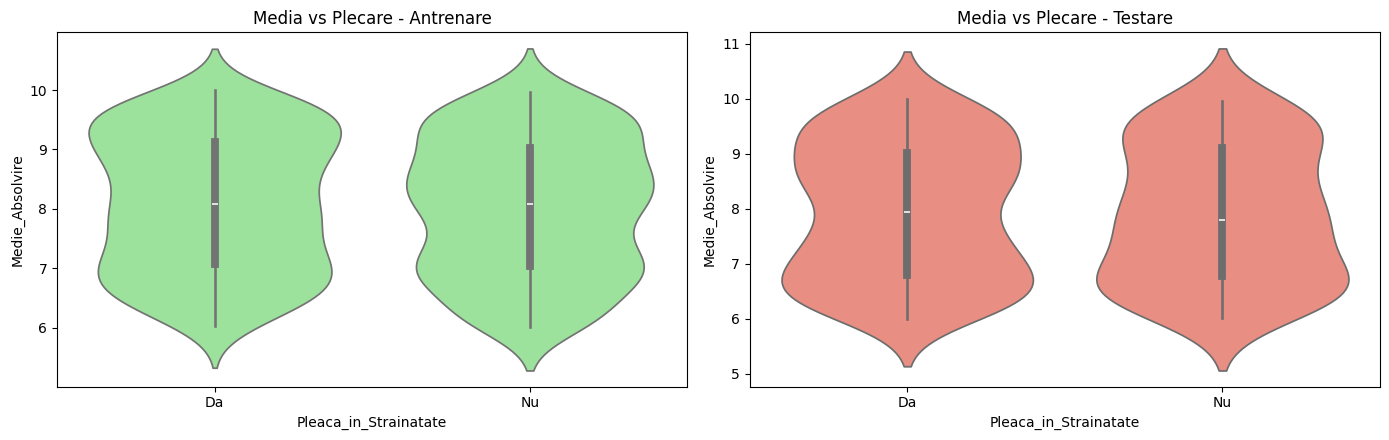

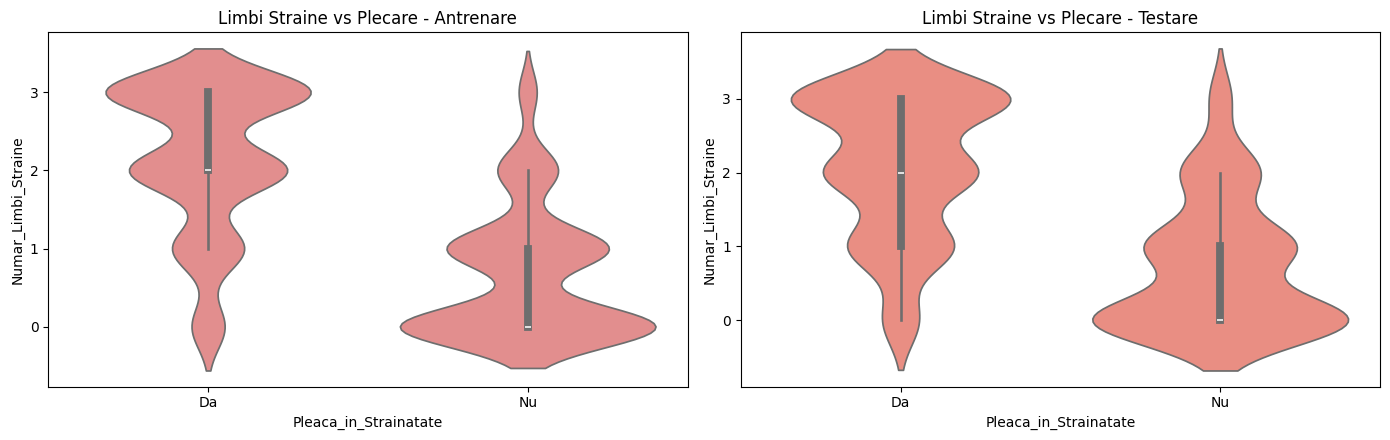

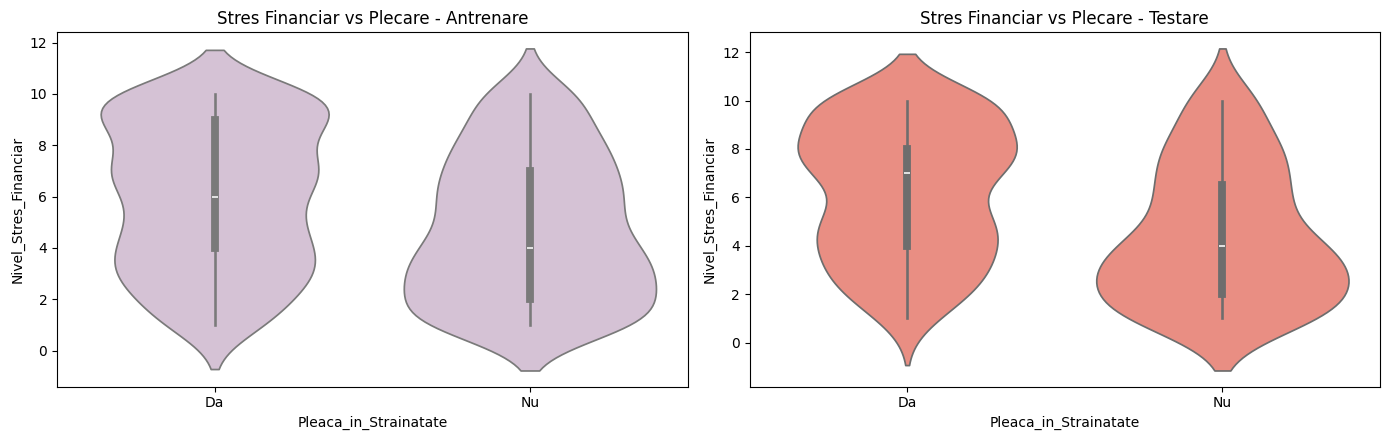

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

coloane_numere = ['Medie_Absolvire', 'Numar_Limbi_Straine', 'Nivel_Stres_Financiar', 'Salariu_Asteptat_RO_Euro']

#heatmap pt antrenare
print("=== Matricea de corelatie ===")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
#calculez corelatia doar pentru coloanele cu numere
matrice_corelatie_train = train_df[coloane_numere].corr()
#desenez heatmap
sns.heatmap(matrice_corelatie_train, annot=True, cmap='Blues', fmt=".2f", ax=axes[0])
axes[0].set_title('Corelatii - Subset Antrenare')

#heatmap pt testare
matrice_corelatie_test = test_df[coloane_numere].corr()
sns.heatmap(matrice_corelatie_test, annot=True, cmap='Oranges', fmt=".2f", ax=axes[1])
axes[1].set_title('Corelatii - Subset Testare')

plt.tight_layout()
plt.show()

#relatia cu variabila tinta
print("\n=== Relatia variabilelor cu intentia de plecare ===")

#relatia cu salariul
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.violinplot(data=train_df, x='Pleaca_in_Strainatate', y='Salariu_Asteptat_RO_Euro', ax=axes[0], color='lightblue')
axes[0].set_title('Salariu vs Plecare - Antrenare')

sns.violinplot(data=test_df, x='Pleaca_in_Strainatate', y='Salariu_Asteptat_RO_Euro', ax=axes[1], color='salmon')
axes[1].set_title('Salariu vs Plecare - Testare')
plt.tight_layout()
plt.show()

#relatia cu media de absolvire
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.violinplot(data=train_df, x='Pleaca_in_Strainatate', y='Medie_Absolvire', ax=axes[0], color='lightgreen')
axes[0].set_title('Media vs Plecare - Antrenare')

sns.violinplot(data=test_df, x='Pleaca_in_Strainatate', y='Medie_Absolvire', ax=axes[1], color='salmon')
axes[1].set_title('Media vs Plecare - Testare')
plt.tight_layout()
plt.show()

#relatia cu limbile straine
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.violinplot(data=train_df, x='Pleaca_in_Strainatate', y='Numar_Limbi_Straine', ax=axes[0], color='lightcoral')
axes[0].set_title('Limbi Straine vs Plecare - Antrenare')

sns.violinplot(data=test_df, x='Pleaca_in_Strainatate', y='Numar_Limbi_Straine', ax=axes[1], color='salmon')
axes[1].set_title('Limbi Straine vs Plecare - Testare')
plt.tight_layout()
plt.show()

#relatia cu stresul financiar
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.violinplot(data=train_df, x='Pleaca_in_Strainatate', y='Nivel_Stres_Financiar', ax=axes[0], color='thistle')
axes[0].set_title('Stres Financiar vs Plecare - Antrenare')

sns.violinplot(data=test_df, x='Pleaca_in_Strainatate', y='Nivel_Stres_Financiar', ax=axes[1], color='salmon')
axes[1].set_title('Stres Financiar vs Plecare - Testare')
plt.tight_layout()
plt.show()

=== Preprocesarea Datelor ===
Datele au fost preprocesate cu succes!

=== Antrenarea Modelului ===
Modelul a fost antrenat si a facut predictiile pe setul de test!

=== Evaluarea Performantei ===
Acuratete (Accuracy): 0.99
Precizie (Precision): 0.99
Recall:               0.99
Scorul F1 (F1-Score): 0.99

Raport complet de clasificare:
              precision    recall  f1-score   support

      Nu (0)       0.99      0.98      0.99       115
      Da (1)       0.99      0.99      0.99       185

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300


=== Matricea de Confuzie ===


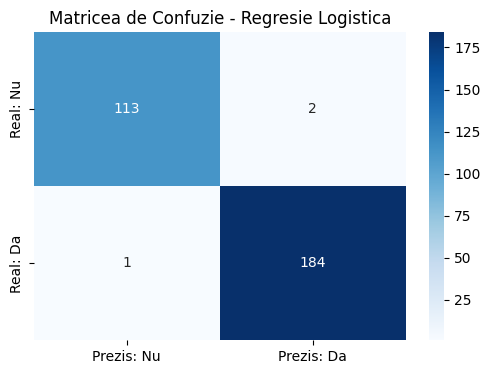

In [6]:
#7-Antrenarea si evaluarea modelului

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import pandas as pd

print("=== Preprocesarea Datelor ===")
#transform variabila Da/Nu in numar(0/1)
y_train = train_df['Pleaca_in_Strainatate'].map({'Da': 1, 'Nu': 0})
y_test = test_df['Pleaca_in_Strainatate'].map({'Da': 1, 'Nu': 0})
#transform celelalte col text in coloane de numere
X_train = pd.get_dummies(train_df.drop('Pleaca_in_Strainatate', axis=1), drop_first=True)
X_test = pd.get_dummies(test_df.drop('Pleaca_in_Strainatate', axis=1), drop_first=True)
#verific daca ambele seturi au acelelasi coloane
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)
#aduc salariile si notele la aceeasi scara
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Datele au fost preprocesate cu succes!\n")

print("=== Antrenarea Modelului ===")
#initializez si antrenez modelul
model = LogisticRegression(random_state=10)
model.fit(X_train_scaled, y_train)
#cer modelului sa faca predictii pe setul de test
y_pred = model.predict(X_test_scaled)
print("Modelul a fost antrenat si a facut predictiile pe setul de test!\n")
print("=== Evaluarea Performantei ===")
#afisez matricile de baza
print(f"Acuratete (Accuracy): {accuracy_score(y_test, y_pred):.2f}")
print(f"Precizie (Precision): {precision_score(y_test, y_pred):.2f}")
print(f"Recall:               {recall_score(y_test, y_pred):.2f}")
print(f"Scorul F1 (F1-Score): {f1_score(y_test, y_pred):.2f}")
print("\nRaport complet de clasificare:")
print(classification_report(y_test, y_pred, target_names=['Nu (0)', 'Da (1)']))

print("\n=== Matricea de Confuzie ===")
#desenez matricea de confuzie
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prezis: Nu', 'Prezis: Da'],
            yticklabels=['Real: Nu', 'Real: Da'])
plt.title('Matricea de Confuzie - Regresie Logistica')
plt.savefig('matrice_confuzie.png', bbox_inches='tight')
plt.show()

In [7]:
!pip install gradio

import gradio as gr
import numpy as np

# Functia care traduce datele din interfata in 0 si 1 pentru model
def prezice_plecarea(medie, limbi, salariu, stres, fac, erasmus, exp):
    # Cream tabelul exact cum il asteapta algoritmul, in ordinea coloanelor
    date = np.array([[
        medie, limbi, salariu, stres,
        1 if fac == "IT" else 0, 1 if fac == "Litere" else 0, 1 if fac == "Medicina" else 0,
        1 if erasmus == "Nu" else 0, 1 if exp == "Nu" else 0
    ]])

    # Scalam si prezicem
    date_scalate = scaler.transform(date)
    prob = model.predict_proba(date_scalate)[0]

    # Afisam rezultatul text
    if model.predict(date_scalate)[0] == 1:
        rezultat = f"Pleaca din tara! (Siguranta: {prob[1]*100:.1f}%)"
    else:
        rezultat = f"Ramane in tara! (Siguranta: {prob[0]*100:.1f}%)"

    return rezultat, "matrice_confuzie.png"

# Desenam butoanele si casutele
gr.Interface(
    fn=prezice_plecarea,
    inputs=[
        gr.Number(label="Medie Absolvire"),
        gr.Number(label="Numar Limbi Straine"),
        gr.Number(label="Salariu Asteptat"),
        gr.Slider(1, 10, label="Stres Financiar"),
        gr.Radio(["IT", "Litere", "Medicina", "Drept"], label="Facultate"),
        gr.Radio(["Nu", "Da"], label="Erasmus?"),
        gr.Radio(["Nu", "Da"], label="Experienta?")
    ],
    outputs=[
        gr.Textbox(label="Decizia Algoritmului"),
        gr.Image(label="Matricea de Confuzie (Performanta)")
    ],
    title="Predictor Emigrare Studenti"
).launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d8a02eb565b05a033a.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://d8a02eb565b05a033a.gradio.live
